# 2-14 종목 한 장 보기 — 뉴스·공시·IR·리포트와 52주 주가를 한 화면에

**질문 예시:** "삼성전자 최근 1년 문서 흐름이랑 주가 한 번에 보여줘", "에코프로비엠 최근 공시·IR·리포트 최신 것만 정리해줘"

종목 하나를 정하면 다음을 한 번에 모읍니다.
- 최근 1년 **뉴스·공시·IR·증권사 리포트** 건수와 월별 추이
- 각 종류의 **최신 목록**(뉴스는 이슈 카테고리로 태그)
- **52주 주가 차트**에 주요 공시일·IR 날짜 표시

종목 지정은 모든 문서 종류에서 `securities.symbol:6자리`로 합니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/14_stock_dashboard.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
STOCK = "005930"
N_LATEST = 5

ISSUE_PRESETS = {
    "계약/수주": "(수주 and 체결) or (수주 and 공급) or (계약 and 체결) or (계약 and 공급)",
    "인수/투자": "인수 or 합병 or 분할 or 영업양도 or 영업양수 or 엠앤에이 or 출자",
    "실적": "실적 or 매출 or 영업이익 or 어닝",
    "증자/감자": "증자 or 감자 or 주식교환 or 주식이전 or 우회상장",
    "주주환원": "배당 or 자사주 or 소각 or 주주환원",
    "소송/규제": "소송 or 횡령 or 배임 or 공소 or 기소 or 혐의 or 제재",
}
ROUTINE = "소유상황보고서|소유주식변동|대량보유|상품ㆍ용역거래|기업설명회|증권발행실적|정정"   # 차트에서 뺄 일상 공시

def doc_pages(category, section, query, date_from, date_to, pages=1, count=100):
    """doc_search 와 같은 표를 주되, 페이지가 count보다 적게 와도 전체 건수에 닿을 때까지 다음 페이지를 받습니다.
    (서버가 중복을 빼고 주는지 한 페이지가 80~90건으로 오는 일이 흔합니다.)"""
    raw, total = [], 0
    for p in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},{json.dumps(query, ensure_ascii=False)},'
             f'count={count},page={p},date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        raw += docs
        if not docs or p * count >= total:
            break
    rows = [{"created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
             "publisher": x.get("publisher"), "title": " ".join(str(x.get("title") or "").split()),
             "stocks": ", ".join(s.get("name", "") for s in x.get("securities") or []),
             "symbols": ", ".join(s.get("symbol", "") for s in x.get("securities") or []),
             "polarity": _polarity(x), "url": x.get("content_url")} for x in raw]
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols).drop_duplicates("url")

def issue_tags(title):
    tags = []
    for name, expr in ISSUE_PRESETS.items():
        for term in expr.split(" or "):
            words = [w.strip(" ()") for w in term.split(" and ")]
            if all(w in title for w in words):
                tags.append(name); break
    return tags

u = universe(); u["code"] = u.symbol.str.replace("KRX:", "", regex=False)
me = u[u.code == STOCK].iloc[0]
print(f"{me['name']} ({STOCK}, {me.market}) — {me.industry_name}")

삼성전자 (005930, KOSPI) — 이동전화기 제조업


## 1. 최근 1년 문서 건수와 월별 추이
건수는 `total_matches`, 추이는 `DocumentTrends`(월별)로 받습니다. 문서를 다 받지 않아도 됩니다.

In [4]:
d1y = (pd.Timestamp(ASOF) - pd.DateOffset(years=1) + pd.Timedelta(days=1)).date()
KINDS = {"뉴스": ("news", []), "공시": ("company", ["disclosure"]), "IR": ("company", ["ir"]), "리포트": ("research", [])}
q = f"securities.symbol:{STOCK}"
totals, monthly = {}, {}
for k, (cat, sec) in KINDS.items():
    t = doc_trends(cat, sec, q, d1y, ASOF, interval="1M")
    monthly[k] = t.set_index(t.date.dt.strftime("%Y-%m"))["count"]
    totals[k] = int(t["count"].sum())
print("최근 1년 건수:", totals)
m = pd.DataFrame(monthly).fillna(0).astype(int)
m.tail(6)

최근 1년 건수: {'뉴스': 90902, '공시': 2919, 'IR': 5, '리포트': 161}


,뉴스,공시,IR,리포트
date,,,,
2026-06,7130,27,0,11
2026-07,8649,788,1,29
2026-08,5530,50,0,9
2026-09,5995,10,1,8
2026-10,6669,32,1,22
2026-11,4445,24,0,5


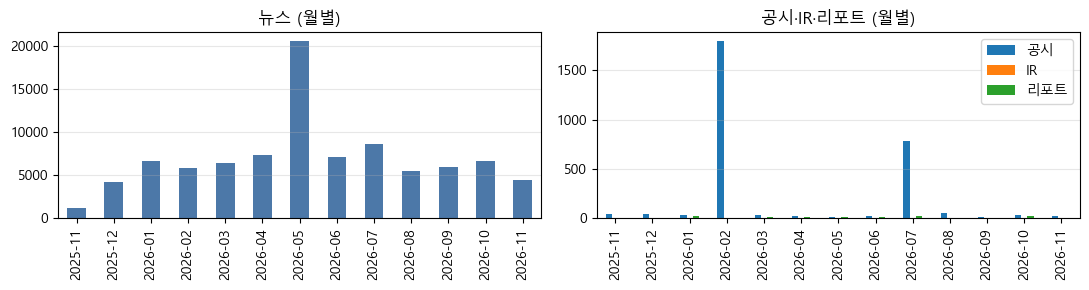

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [1, 1]})
m["뉴스"].plot.bar(ax=axes[0], color="#4C78A8", title="뉴스 (월별)")
m[["공시", "IR", "리포트"]].plot.bar(ax=axes[1], title="공시·IR·리포트 (월별)")
for a in axes:
    a.grid(alpha=.3, axis="y"); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 2. 최신 목록

In [6]:
d2w = (pd.Timestamp(ASOF) - pd.Timedelta(days=13)).date()
_, news = doc_pages("news", [], q, d2w, ASOF, pages=5)
news["이슈"] = news.title.map(issue_tags)
print(f"최근 2주 뉴스 {len(news)}건 | 이슈별:", news.이슈.explode().value_counts().to_dict(),
      "| 긍부정:", news.polarity.value_counts().to_dict())
news[news.이슈.str.len() > 0][["created_at", "publisher", "title", "이슈", "polarity"]].head(N_LATEST)

최근 2주 뉴스 432건 | 이슈별: {'인수/투자': 20, '주주환원': 14, '실적': 11, '계약/수주': 1} | 긍부정: {'중립': 357, '긍정': 45, '부정': 30}


,created_at,publisher,title,이슈,polarity
10,2026-11-24 19:22:00,한겨레,"삼성 준감위 “삼성전자 주주환원 유보, 이재용 증여세 이해상충 아니다”",[주주환원],부정
11,2026-11-24 19:11:00,헤럴드경제,"삼성 준감위 “삼성전자 주주환원 결정 시점, 이해상충 해당 안돼”",[주주환원],부정
12,2026-11-24 19:11:00,전자신문,"삼성 준감위 “삼성전자 주주환원 결정, 이해상충 아냐”",[주주환원],부정
13,2026-11-24 19:03:00,파이낸셜뉴스,"삼성 준감위 ""삼성전자 주주환원 결정, 준법 위반·이해상충 아니다""",[주주환원],중립
14,2026-11-24 18:55:00,한국일보,"준감위 ""삼성전자 주주환원 결정 과정, 준법위반·이해상충 아니다""",[주주환원],중립


In [7]:
latest = {}
for k in ("공시", "IR", "리포트"):
    cat, sec = KINDS[k]
    qq = q if k != "공시" else f"{q} and !title:소유상황보고서"
    _, df = doc_search(cat, sec, qq, d1y, ASOF, count=N_LATEST)
    latest[k] = df
    print(f"\n■ {k} 최신 {len(df)}건")
    print(df[["created_at", "publisher", "title"]].to_string(index=False, max_colwidth=50))


■ 공시 최신 5건
         created_at publisher                 title
2026-11-16 16:46:38      삼성전자       분기보고서 (2026.09)
2026-11-13 17:16:37      삼성전자        최대주주등소유주식변동신고서
2026-11-13 16:46:33      삼성전자 동일인등출자계열회사와의상품ㆍ용역거래변경
2026-11-13 16:43:16      삼성전자 동일인등출자계열회사와의상품ㆍ용역거래변경
2026-11-13 16:43:16      삼성전자 동일인등출자계열회사와의상품ㆍ용역거래변경



■ IR 최신 5건
         created_at publisher                              title
2026-10-29 13:38:39      삼성전자                  2026년 3분기 경영실적 발표
2026-09-08 10:25:11      삼성전자 모듈러 주택 생산에 휴머노이드 투입…‘건설 자동화’ 불 지핀다
2026-07-30 17:41:59      삼성전자                  2026년 2분기 경영실적 발표
2026-04-30 13:15:33      삼성전자                  2026년 1분기 경영실적 발표
2026-01-29 13:49:46      삼성전자                  2025년 4분기 경영실적 발표



■ 리포트 최신 5건
         created_at publisher                                   title
2026-11-20 14:33:35      삼성증권 국내 긴급시황(2026.11.20): AI 불확실성과 긴축 우려에 하락
2026-11-16 08:04:21    한국투자증권         글로벌 자산전략:Weekly: 업종 다변화가 필요한 주간
2026-11-12 09:00:00    미래에셋대우                         반도체 엔비디아 이슈 코멘트
2026-11-06 09:00:00    신한금융투자           Global IT H/W Weekly(11월 1주차)
2026-11-04 11:00:09      iM증권                             STRESS TEST


## 3. 52주 주가와 공시·IR 날짜
공시 중 소유상황 보고 같은 일상 공시는 빼고, 남은 공시와 IR 자료 날짜를 주가 위에 표시합니다.

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).
1년 공시 2,919건 → 소유상황 보고 등 제외 128건 → 차트 표시 94건, IR 5건


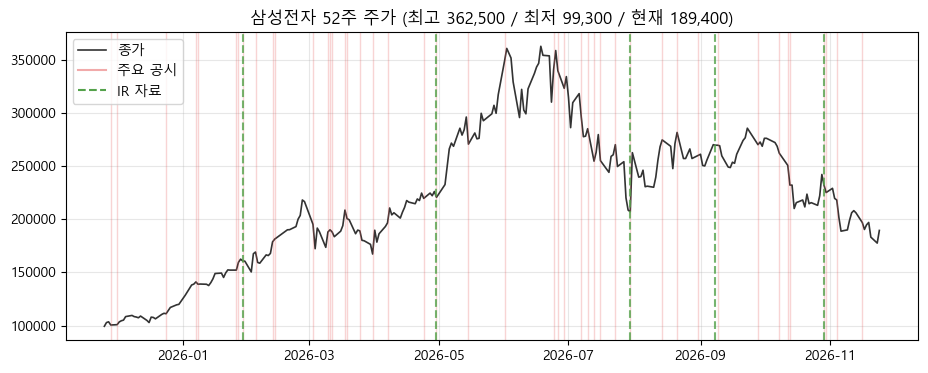

In [8]:
px = stock_prices(f"KRX:{STOCK}", d1y, ASOF, columns=["close", "volume"]).set_index("date")
# 1년 공시의 대부분이 임원·주요주주 소유상황 보고라, 검색 단계에서 제외(!title:)하고 받습니다
not_routine = " and ".join(f"!title:{w}" for w in ["소유상황보고서", "소유주식변동", "대량보유"])
n_all, _ = doc_pages("company", ["disclosure"], q, d1y, ASOF, count=1)
_, disc = doc_pages("company", ["disclosure"], f"{q} and {not_routine}", d1y, ASOF, pages=3)
key = disc[~disc.title.str.contains(ROUTINE, regex=True)].copy()
_, irs = doc_search("company", ["ir"], q, d1y, ASOF, count=100)
print(PRICE_NOTICE)
print(f"1년 공시 {n_all:,}건 → 소유상황 보고 등 제외 {len(disc)}건 → 차트 표시 {len(key)}건, IR {len(irs)}건")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(px.index, px.close, color="#333", lw=1.2, label="종가")
for d in key.created_at.dt.normalize().unique():
    ax.axvline(d, color="#E45756", alpha=.25, lw=1)
for d in irs.created_at.dt.normalize().unique():
    ax.axvline(d, color="#54A24B", alpha=.8, lw=1.5, ls="--")
ax.plot([], [], color="#E45756", alpha=.5, label="주요 공시"); ax.plot([], [], color="#54A24B", ls="--", label="IR 자료")
ax.set_title(f"{me['name']} 52주 주가 (최고 {px.close.max():,.0f} / 최저 {px.close.min():,.0f} / 현재 {px.close.iloc[-1]:,.0f})")
ax.legend(loc="upper left"); ax.grid(alpha=.3); plt.show()

In [9]:
# 주요 공시 직후 5거래일 수익률 (참고)
rows = []
for _, r in key.sort_values("created_at").iterrows():
    d = r.created_at.normalize() + (pd.Timedelta(days=1) if r.created_at.hour >= 15 else pd.Timedelta(0))
    idx = px.index[px.index >= d]
    if len(idx) > 5:
        p0 = px.close[px.index < idx[0]].iloc[-1] if (px.index < idx[0]).any() else px.close[idx[0]]
        rows.append({"날짜": r.created_at.strftime("%Y-%m-%d %H:%M"), "공시": r.title[:40],
                     "5거래일 수익률(%)": round((px.close[idx[4]] / p0 - 1) * 100, 1)})
ev = pd.DataFrame(rows)
ev = ev.assign(일=ev.날짜.str[:10]).drop_duplicates(["일", "공시"]).drop(columns="일")   # 같은 날 같은 공시는 한 번만
ev.tail(10)

,날짜,공시,5거래일 수익률(%)
80,2026-10-29 09:58,현금ㆍ현물배당결정,-9.9
81,2026-10-29 10:03,장래사업ㆍ경영계획(공정공시),-9.9
82,2026-10-29 16:23,특수관계인에대한출자,-13.1
83,2026-10-29 16:28,특수관계인과의보험거래,-13.1
84,2026-10-29 16:43,특수관계인에대한증여,-13.1
86,2026-10-29 16:43,주요사항보고서(자기주식처분결정),-13.1
89,2026-10-29 17:03,기타경영사항(자율공시),-13.1
91,2026-10-30 16:31,특수관계인으로부터주식의취득,-16.1
92,2026-11-04 16:56,자기주식처분결과보고서,-5.5
93,2026-11-16 16:46,분기보고서 (2026.09),-9.8


## 결과 읽는 법과 한계
- **뉴스 건수는 "그 종목이 주제인 기사"** 기준입니다(본문에 이름만 나온 기사는 빠짐). 동명 오인식 기사가 섞일 수 있습니다.
- **이슈 태그는 제목 키워드 매칭**이라 거칩니다. '투자'처럼 넓은 단어는 묶음에서 뺐습니다.
- 공시 후 수익률은 다른 사건과 시장 움직임이 섞인 참고값입니다. 제대로 보려면 [2-01 공시 이벤트 스터디](01_disclosure_event_study.ipynb)를 쓰세요.